# HW #3: 스타벅스 고객 중심 테이블 구축

## 과제 목표
1. 주어진 데이터 테이블의 ERD(Entity Relationship Diagram)를 작성한다.
2. 고객별 오퍼(Offer)에 대한 반응률을 관리하는 **고객 중심 마트 테이블(Customer-Centric Mart)**을 구축한다.

---

## 데이터 설명

| 테이블명 | 설명 |
|---|---|
| `portfolio.csv` | 오퍼(Offer) 정보 — 총 10종의 오퍼 |
| `profile.csv` | 고객(Customer) 정보 — 인구통계학적 속성 |
| `transcript.csv` | 이벤트 로그 — 고객의 오퍼 수신·열람·완료 및 거래 기록 |




---
## 1단계: 라이브러리 임포트 및 데이터 로드

In [2]:
import os

# Data folder: ../data (default) — override with the DATA_DIR environment variable.
DATA_DIR = os.environ.get("DATA_DIR") or next(
    (p for p in ["../data", "data"] if os.path.isdir(p)), "../data")

# On Google Colab, read the files from Google Drive instead.
try:
    from google.colab import drive
    drive.mount('/content/drive')
    DATA_DIR = '/content/drive/MyDrive/datasets'
except ImportError:
    pass


In [3]:
import numpy as np
import pandas as pd
import duckdb
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.stats import chi2_contingency

def dfsql(query): # SQL 쿼리를 실행하여 pandas DataFrame으로 반환한다.
    return duckdb.query(query).df()

df_offer      = pd.read_csv(os.path.join(DATA_DIR, 'portfolio.csv'))   # 오퍼 정보
df_customer   = pd.read_csv(os.path.join(DATA_DIR, 'profile.csv'))     # 고객 정보
df_transcript = pd.read_csv(os.path.join(DATA_DIR, 'transcript.csv'))  # 이벤트 로그

print(f'  - df_offer     : {df_offer.shape}')
print(f'  - df_customer  : {df_customer.shape}')
print(f'  - df_transcript: {df_transcript.shape}')

  - df_offer     : (10, 7)
  - df_customer  : (17000, 6)
  - df_transcript: (306534, 5)


---
## 2단계: 탐색적 데이터 분석(EDA)

In [4]:
print('[portfolio] 오퍼 테이블 컬럼 설명')
print('  reward     : 오퍼 완료 시 제공되는 보상 포인트')
print('  channels   : 오퍼 발송 채널 (web, email, mobile, social)')
print('  difficulty : 오퍼 달성 최소 소비 금액')
print('  duration   : 오퍼 유효 기간 (일 단위)')
print('  offer_type : bogo(1+1) / discount(할인) / informational(정보성)')
print('  id         : 오퍼 고유 식별자')
print(df_offer.dtypes)
df_offer.head(10)

[portfolio] 오퍼 테이블 컬럼 설명
  reward     : 오퍼 완료 시 제공되는 보상 포인트
  channels   : 오퍼 발송 채널 (web, email, mobile, social)
  difficulty : 오퍼 달성 최소 소비 금액
  duration   : 오퍼 유효 기간 (일 단위)
  offer_type : bogo(1+1) / discount(할인) / informational(정보성)
  id         : 오퍼 고유 식별자
Unnamed: 0     int64
reward         int64
channels      object
difficulty     int64
duration       int64
offer_type    object
id            object
dtype: object


,Unnamed: 0,reward,channels,difficulty,duration,offer_type,id
0,0,10,"['email', 'mobile', 'social']",10,7,bogo,ae264e3637204a6fb9bb56bc8210ddfd
1,1,10,"['web', 'email', 'mobile', 'social']",10,5,bogo,4d5c57ea9a6940dd891ad53e9dbe8da0
2,2,0,"['web', 'email', 'mobile']",0,4,informational,3f207df678b143eea3cee63160fa8bed
3,3,5,"['web', 'email', 'mobile']",5,7,bogo,9b98b8c7a33c4b65b9aebfe6a799e6d9
4,4,5,"['web', 'email']",20,10,discount,0b1e1539f2cc45b7b9fa7c272da2e1d7
5,5,3,"['web', 'email', 'mobile', 'social']",7,7,discount,2298d6c36e964ae4a3e7e9706d1fb8c2
6,6,2,"['web', 'email', 'mobile', 'social']",10,10,discount,fafdcd668e3743c1bb461111dcafc2a4
7,7,0,"['email', 'mobile', 'social']",0,3,informational,5a8bc65990b245e5a138643cd4eb9837
8,8,5,"['web', 'email', 'mobile', 'social']",5,5,bogo,f19421c1d4aa40978ebb69ca19b0e20d
9,9,2,"['web', 'email', 'mobile']",10,7,discount,2906b810c7d4411798c6938adc9daaa5


In [5]:
print('[profile] 고객 테이블 컬럼 설명')
print('  gender           : 성별 (M/F)')
print('  age              : 나이')
print('  id               : 고객 고유 식별자')
print('  became_member_on : 회원 가입일')
print('  income           : 연간 소득')
print(df_customer.dtypes)
df_customer.head()

[profile] 고객 테이블 컬럼 설명
  gender           : 성별 (M/F)
  age              : 나이
  id               : 고객 고유 식별자
  became_member_on : 회원 가입일
  income           : 연간 소득
Unnamed: 0            int64
gender               object
age                   int64
id                   object
became_member_on      int64
income              float64
dtype: object


,Unnamed: 0,gender,age,id,became_member_on,income
0,0,NaN,118,68be06ca386d4c31939f3a4f0e3dd783,20170212,NaN
1,1,F,55,0610b486422d4921ae7d2bf64640c50b,20170715,112000.0
2,2,NaN,118,38fe809add3b4fcf9315a9694bb96ff5,20180712,NaN
3,3,F,75,78afa995795e4d85b5d9ceeca43f5fef,20170509,100000.0
4,4,NaN,118,a03223e636434f42ac4c3df47e8bac43,20170804,NaN


In [6]:
print('[transcript] 이벤트 로그 테이블 컬럼 설명')
print('  person : 고객 식별자 (profile.id 와 연결)')
print('  event  : 이벤트 유형')
print('  value  : 이벤트 상세 정보 (offer id 또는 거래 금액)')
print('  time   : 테스트 시작 후 경과 시간 (시간 단위)')
print(df_transcript.dtypes)
df_transcript.head()

[transcript] 이벤트 로그 테이블 컬럼 설명
  person : 고객 식별자 (profile.id 와 연결)
  event  : 이벤트 유형
  value  : 이벤트 상세 정보 (offer id 또는 거래 금액)
  time   : 테스트 시작 후 경과 시간 (시간 단위)
Unnamed: 0     int64
person        object
event         object
value         object
time           int64
dtype: object


,Unnamed: 0,person,event,value,time
0,0,78afa995795e4d85b5d9ceeca43f5fef,offer received,{'offer id': '9b98b8c7a33c4b65b9aebfe6a799e6d9'},0
1,1,a03223e636434f42ac4c3df47e8bac43,offer received,{'offer id': '0b1e1539f2cc45b7b9fa7c272da2e1d7'},0
2,2,e2127556f4f64592b11af22de27a7932,offer received,{'offer id': '2906b810c7d4411798c6938adc9daaa5'},0
3,3,8ec6ce2a7e7949b1bf142def7d0e0586,offer received,{'offer id': 'fafdcd668e3743c1bb461111dcafc2a4'},0
4,4,68617ca6246f4fbc85e91a2a49552598,offer received,{'offer id': '4d5c57ea9a6940dd891ad53e9dbe8da0'},0


In [7]:
# 이벤트 종류 확인
print(df_transcript['event'].value_counts())

event
transaction        138953
offer received      76277
offer viewed        57725
offer completed     33579
Name: count, dtype: int64


---
## 3단계: ERD (Entity Relationship Diagram)

아래는 세 테이블 간의 관계를 나타낸 ERD이다.

```
┌─────────────────────────────────────┐
│          portfolio (오퍼 정보)        │
├─────────────────────────────────────┤
│ PK  id           VARCHAR            │
│     offer_type   VARCHAR            │
│     reward       INTEGER            │
│     difficulty   INTEGER            │
│     duration     INTEGER            │
│     channels     VARCHAR            │
└──────────────────┬──────────────────┘
                   │ 1
                   │  (오퍼 id 기준 참조)
                   │ N
┌──────────────────▼──────────────────┐
│      transcript (이벤트 로그)         │
├─────────────────────────────────────┤
│ PK  index        INTEGER            │
│ FK  person       VARCHAR ──────────┐│
│ FK  offer_id     VARCHAR (value에 ) ││
│     event        VARCHAR            ││
│     value        VARCHAR            ││
│     time         INTEGER            ││
└─────────────────────────────────────┘│
                   | N                 │
                   │ (person = id)     │
                   │ 1                 │
┌──────────────────▼──────────────────┐│
│         profile (고객 정보)           ││
├─────────────────────────────────────┤│
│ PK  id               VARCHAR ◄──────┘│
│     gender           VARCHAR         │
│     age              INTEGER         │
│     became_member_on DATE            │
│     income           FLOAT           │
└─────────────────────────────────────┘

관계 요약:
  - profile(id) 1 : N transcript(person)
    → 한 고객은 여러 이벤트를 가질 수 있음
  - portfolio(id) 1 : N transcript(value 내 offer_id)
    → 하나의 오퍼는 여러 이벤트 로그에 등장할 수 있음
```

---
## 4단계: 데이터 전처리

In [8]:
print(df_offer)

   Unnamed: 0  reward                              channels  difficulty  \
0           0      10         ['email', 'mobile', 'social']          10   
1           1      10  ['web', 'email', 'mobile', 'social']          10   
2           2       0            ['web', 'email', 'mobile']           0   
3           3       5            ['web', 'email', 'mobile']           5   
4           4       5                      ['web', 'email']          20   
5           5       3  ['web', 'email', 'mobile', 'social']           7   
6           6       2  ['web', 'email', 'mobile', 'social']          10   
7           7       0         ['email', 'mobile', 'social']           0   
8           8       5  ['web', 'email', 'mobile', 'social']           5   
9           9       2            ['web', 'email', 'mobile']          10   

   duration     offer_type                                id  
0         7           bogo  ae264e3637204a6fb9bb56bc8210ddfd  
1         5           bogo  4d5c57ea9a6940dd891a

In [9]:
# Unnamed 인덱스 컬럼 제거
df_offer      = df_offer.drop('Unnamed: 0', axis=1)
df_customer   = df_customer.drop('Unnamed: 0', axis=1)
df_transcript = df_transcript.drop('Unnamed: 0', axis=1)

In [10]:
print(df_customer['income'].head())

0         NaN
1    112000.0
2         NaN
3    100000.0
4         NaN
Name: income, dtype: float64


In [11]:
# 소득(income)이 결측인 고객 제거
missing_income = df_customer[df_customer['income'].isna()]
print(f'소득 결측 고객 수: {len(missing_income)}명')

소득 결측 고객 수: 2175명


In [12]:
id_to_remove = missing_income['id']
df_customer = df_customer[~df_customer['id'].isin(id_to_remove)].reset_index(drop=True)

# 회원 가입일을 datetime 형식으로 변환
df_customer['became_member_on'] = pd.to_datetime(df_customer['became_member_on'], format='%Y%m%d')

# 가입 연도 파생 변수 생성
df_customer['n_year'] = df_customer['became_member_on'].dt.year

print(f'전처리 후 고객 수: {len(df_customer)}명')
df_customer.head()

전처리 후 고객 수: 14825명


,gender,age,id,became_member_on,income,n_year
0,F,55,0610b486422d4921ae7d2bf64640c50b,2017-07-15,112000.0,2017
1,F,75,78afa995795e4d85b5d9ceeca43f5fef,2017-05-09,100000.0,2017
2,M,68,e2127556f4f64592b11af22de27a7932,2018-04-26,70000.0,2018
3,M,65,389bc3fa690240e798340f5a15918d5c,2018-02-09,53000.0,2018
4,M,58,2eeac8d8feae4a8cad5a6af0499a211d,2017-11-11,51000.0,2017


In [13]:
print(df_transcript.head())

                             person           event  \
0  78afa995795e4d85b5d9ceeca43f5fef  offer received   
1  a03223e636434f42ac4c3df47e8bac43  offer received   
2  e2127556f4f64592b11af22de27a7932  offer received   
3  8ec6ce2a7e7949b1bf142def7d0e0586  offer received   
4  68617ca6246f4fbc85e91a2a49552598  offer received   

                                              value  time  
0  {'offer id': '9b98b8c7a33c4b65b9aebfe6a799e6d9'}     0  
1  {'offer id': '0b1e1539f2cc45b7b9fa7c272da2e1d7'}     0  
2  {'offer id': '2906b810c7d4411798c6938adc9daaa5'}     0  
3  {'offer id': 'fafdcd668e3743c1bb461111dcafc2a4'}     0  
4  {'offer id': '4d5c57ea9a6940dd891ad53e9dbe8da0'}     0  


In [14]:
# time 컬럼명을 hours_since_start 로 변경하여 의미를 명확히 함
df_transcript.rename(columns={'time': 'hours_since_start'}, inplace=True)

In [15]:
# value 컬럼을 dict_key, dict_value 두 컬럼으로 분리
df_transcript['dict_key']   = df_transcript['value'].str.split(':').str[0].str.split('{').str[1]
df_transcript['dict_value'] = df_transcript['value'].str.split(':').str[1].str.split('}').str[0]

In [16]:
# 따옴표 및 불필요한 문자열 제거
df_transcript['dict_key']   = df_transcript['dict_key'].str.replace("'", "", regex=False)
df_transcript['dict_value'] = df_transcript['dict_value'].str.replace("'", "", regex=False)
df_transcript['dict_value'] = df_transcript['dict_value'].str.replace(", reward", "", regex=False)

In [17]:
print('dict_key 유형:', df_transcript['dict_key'].unique())
df_transcript.head()

dict_key 유형: ['offer id' 'amount' 'offer_id']


,person,event,value,hours_since_start,dict_key,dict_value
0,78afa995795e4d85b5d9ceeca43f5fef,offer received,{'offer id': '9b98b8c7a33c4b65b9aebfe6a799e6d9'},0,offer id,9b98b8c7a33c4b65b9aebfe6a799e6d9
1,a03223e636434f42ac4c3df47e8bac43,offer received,{'offer id': '0b1e1539f2cc45b7b9fa7c272da2e1d7'},0,offer id,0b1e1539f2cc45b7b9fa7c272da2e1d7
2,e2127556f4f64592b11af22de27a7932,offer received,{'offer id': '2906b810c7d4411798c6938adc9daaa5'},0,offer id,2906b810c7d4411798c6938adc9daaa5
3,8ec6ce2a7e7949b1bf142def7d0e0586,offer received,{'offer id': 'fafdcd668e3743c1bb461111dcafc2a4'},0,offer id,fafdcd668e3743c1bb461111dcafc2a4
4,68617ca6246f4fbc85e91a2a49552598,offer received,{'offer id': '4d5c57ea9a6940dd891ad53e9dbe8da0'},0,offer id,4d5c57ea9a6940dd891ad53e9dbe8da0


---
## 5단계: 고객 중심 마트 테이블(Customer-Centric Mart) 구축

### 5-1. 오퍼 유형별 ID 목록 생성

In [18]:
# 오퍼 유형별 ID 리스트 추출
bogo_offer_id        = df_offer[df_offer['offer_type'] == 'bogo']['id'].tolist()
discount_offer_id    = df_offer[df_offer['offer_type'] == 'discount']['id'].tolist()
information_offer_id = df_offer[df_offer['offer_type'] == 'informational']['id'].tolist()

In [19]:
print(f'BOGO(1+1) 오퍼 ID ({len(bogo_offer_id)}개):')
for oid in bogo_offer_id:
    print(f'  {oid}')
print(f'\nDiscount(할인) 오퍼 ID ({len(discount_offer_id)}개):')
for oid in discount_offer_id:
    print(f'  {oid}')
print(f'\nInformational(정보성) 오퍼 ID ({len(information_offer_id)}개):')
for oid in information_offer_id:
    print(f'  {oid}')

BOGO(1+1) 오퍼 ID (4개):
  ae264e3637204a6fb9bb56bc8210ddfd
  4d5c57ea9a6940dd891ad53e9dbe8da0
  9b98b8c7a33c4b65b9aebfe6a799e6d9
  f19421c1d4aa40978ebb69ca19b0e20d

Discount(할인) 오퍼 ID (4개):
  0b1e1539f2cc45b7b9fa7c272da2e1d7
  2298d6c36e964ae4a3e7e9706d1fb8c2
  fafdcd668e3743c1bb461111dcafc2a4
  2906b810c7d4411798c6938adc9daaa5

Informational(정보성) 오퍼 ID (2개):
  3f207df678b143eea3cee63160fa8bed
  5a8bc65990b245e5a138643cd4eb9837


### 5-2. 고객별 오퍼 유형 수신 횟수 계산 함수 정의

In [20]:
def event_cnt(offer_id_list):
    """
    고객이 수신한 오퍼 ID 리스트로부터
    BOGO, Discount, Informational 오퍼 수신 횟수를 각각 계산하여 반환한다.
    """
    bogo_cnt = discount_cnt = information_cnt = 0
    for oid in offer_id_list:
        oid = oid.strip()
        if oid in bogo_offer_id:        bogo_cnt        += 1
        if oid in discount_offer_id:    discount_cnt    += 1
        if oid in information_offer_id: information_cnt += 1
    return bogo_cnt, discount_cnt, information_cnt

### 5-3. 고객 ID 목록 추출 및 개별 고객 트랜잭션 패턴 예시 확인

In [21]:
customers = df_customer['id'].tolist()
print(f'분석 대상 고객 수: {len(customers):,}명')

분석 대상 고객 수: 14,825명


In [22]:
# 특정 고객의 이벤트 패턴 예시 (참조용)
sample_id = '0610b486422d4921ae7d2bf64640c50b'
_tmp = df_transcript[df_transcript['person'] == sample_id]
print(f'고객 [{sample_id[:8]}...] 의 이벤트 기록:')
_tmp

고객 [0610b486...] 의 이벤트 기록:


,person,event,value,hours_since_start,dict_key,dict_value
20282,0610b486422d4921ae7d2bf64640c50b,transaction,{'amount': 21.51},18,amount,21.51
49501,0610b486422d4921ae7d2bf64640c50b,transaction,{'amount': 32.28},144,amount,32.28
150597,0610b486422d4921ae7d2bf64640c50b,offer received,{'offer id': '9b98b8c7a33c4b65b9aebfe6a799e6d9'},408,offer id,9b98b8c7a33c4b65b9aebfe6a799e6d9
201571,0610b486422d4921ae7d2bf64640c50b,offer received,{'offer id': '3f207df678b143eea3cee63160fa8bed'},504,offer id,3f207df678b143eea3cee63160fa8bed
227842,0610b486422d4921ae7d2bf64640c50b,transaction,{'amount': 23.22},528,amount,23.22
227843,0610b486422d4921ae7d2bf64640c50b,offer completed,{'offer_id': '9b98b8c7a33c4b65b9aebfe6a799e6d9...,528,offer_id,9b98b8c7a33c4b65b9aebfe6a799e6d9


### 5-4. 고객 중심 반응 테이블(Response Table) 생성

모든 고객에 대해 아래 지표를 계산하여 고객 1행(row) 단위의 마트 테이블을 구성한다.

| 컬럼명 | 설명 |
|---|---|
| `offer_received` | 수신한 오퍼 총 건수 |
| `response_cnt` | 완료한(반응한) 오퍼 건수 |
| `tr_cnt` | 거래(구매) 건수 |
| `tr_amt` | 거래 총 금액 |
| `bogo_cnt` | 수신한 BOGO 오퍼 건수 |
| `dc_cnt` | 수신한 Discount 오퍼 건수 |
| `info_cnt` | 수신한 Informational 오퍼 건수 |
| `bogo_response` | 완료한 BOGO 오퍼 건수 |
| `dc_response` | 완료한 Discount 오퍼 건수 |
| `info_response` | 완료한 Informational 오퍼 건수 |

In [23]:
%%time
response_table = []

for cust in customers:
    _tmp = df_transcript[df_transcript['person'] == cust]  # 고객별 이벤트 필터링
    res  = _tmp['event'].value_counts()                    # 이벤트 유형별 집계

    # 오퍼를 한 건이라도 수신한 고객만 분석 대상으로 포함
    if 'offer received' not in res:
        continue

    # 오퍼 완료 횟수
    response_cnt = res.get('offer completed', 0)

    # 거래 정보
    if 'transaction' in res:
        tr_cnt = res['transaction']
        tr_values = list(_tmp[_tmp['event'] == 'transaction']['dict_value'])
        tr_amt = sum(float(v.strip()) for v in tr_values)
    else:
        tr_cnt, tr_amt = 0, 0

    # 수신 오퍼 유형별 횟수
    received_offer_ids = list(_tmp[_tmp['event'] == 'offer received']['dict_value'])
    bogo_cnt, dc_cnt, info_cnt = event_cnt(received_offer_ids)

    # 완료 오퍼 유형별 횟수
    completed_offer_ids = list(_tmp[_tmp['event'] == 'offer completed']['dict_value'])
    bogo_response = dc_response = info_response = 0
    for oid in completed_offer_ids:
        oid = oid.strip()
        if oid in bogo_offer_id:        bogo_response += 1
        if oid in discount_offer_id:    dc_response   += 1
        if oid in information_offer_id: info_response += 1

    response_table.append([
        cust,
        res['offer received'],
        response_cnt,
        tr_cnt, tr_amt,
        bogo_cnt, dc_cnt, info_cnt,
        bogo_response, dc_response, info_response
    ])

response_table = pd.DataFrame(response_table, columns=[
    'id', 'offer_received', 'response_cnt',
    'tr_cnt', 'tr_amt',
    'bogo_cnt', 'dc_cnt', 'info_cnt',
    'bogo_response', 'dc_response', 'info_response'
])

print(f'반응 테이블 생성 완료: {response_table.shape}')
response_table.head()

반응 테이블 생성 완료: (14820, 11)
CPU times: user 8min 20s, sys: 436 ms, total: 8min 21s
Wall time: 8min 26s


,id,offer_received,response_cnt,tr_cnt,tr_amt,bogo_cnt,dc_cnt,info_cnt,bogo_response,dc_response,info_response
0,0610b486422d4921ae7d2bf64640c50b,2,1,3,77.01,1,0,1,1,0,0
1,78afa995795e4d85b5d9ceeca43f5fef,4,3,7,159.27,3,0,1,3,0,0
2,e2127556f4f64592b11af22de27a7932,4,2,3,57.73,1,2,1,1,1,0
3,389bc3fa690240e798340f5a15918d5c,6,5,3,36.43,4,2,0,3,2,0
4,2eeac8d8feae4a8cad5a6af0499a211d,3,1,4,15.62,0,2,1,0,1,0


### 5-5. 고객 정보와 반응 테이블 병합 → 마트 테이블(df_mart) 생성

In [24]:
# 고객 인구통계 정보(df_customer)와 반응 테이블(response_table) 병합
df_mart = pd.merge(df_customer, response_table, how='right', on='id')
print(f'마트 테이블 생성 완료: {df_mart.shape}')
df_mart.head()

마트 테이블 생성 완료: (14820, 16)


,gender,age,id,became_member_on,income,n_year,offer_received,response_cnt,tr_cnt,tr_amt,bogo_cnt,dc_cnt,info_cnt,bogo_response,dc_response,info_response
0,F,55,0610b486422d4921ae7d2bf64640c50b,2017-07-15,112000.0,2017,2,1,3,77.01,1,0,1,1,0,0
1,F,75,78afa995795e4d85b5d9ceeca43f5fef,2017-05-09,100000.0,2017,4,3,7,159.27,3,0,1,3,0,0
2,M,68,e2127556f4f64592b11af22de27a7932,2018-04-26,70000.0,2018,4,2,3,57.73,1,2,1,1,1,0
3,M,65,389bc3fa690240e798340f5a15918d5c,2018-02-09,53000.0,2018,6,5,3,36.43,4,2,0,3,2,0
4,M,58,2eeac8d8feae4a8cad5a6af0499a211d,2017-11-11,51000.0,2017,3,1,4,15.62,0,2,1,0,1,0


### 5-6. 반응률(Response Ratio) 파생 변수 생성

In [25]:
# 전체 오퍼 반응률
df_mart['response_ratio'] = df_mart['response_cnt'] / df_mart['offer_received']

# BOGO 오퍼 반응률
df_mart['bogo_ratio'] = df_mart['bogo_response'] / df_mart['bogo_cnt']

# Discount 오퍼 반응률
df_mart['dc_ratio'] = df_mart['dc_response'] / df_mart['dc_cnt']

# Informational 오퍼 반응률
df_mart['info_ratio'] = df_mart['info_response'] / df_mart['info_cnt']

print('반응률 변수 생성 완료')
df_mart[['id', 'response_ratio', 'bogo_ratio', 'dc_ratio', 'info_ratio']].head(10)

반응률 변수 생성 완료


,id,response_ratio,bogo_ratio,dc_ratio,info_ratio
0,0610b486422d4921ae7d2bf64640c50b,0.500000,1.00,NaN,0.0
1,78afa995795e4d85b5d9ceeca43f5fef,0.750000,1.00,NaN,0.0
2,e2127556f4f64592b11af22de27a7932,0.500000,1.00,0.500000,0.0
3,389bc3fa690240e798340f5a15918d5c,0.833333,0.75,1.000000,NaN
4,2eeac8d8feae4a8cad5a6af0499a211d,0.333333,NaN,0.500000,0.0
5,aa4862eba776480b8bb9c68455b8c2e1,0.600000,1.00,0.000000,0.0
6,e12aeaf2d47d42479ea1c4ac3d8286c6,0.166667,0.00,0.200000,NaN
7,31dda685af34476cad5bc968bdb01c53,0.666667,NaN,0.666667,NaN
8,62cf5e10845442329191fc246e7bcea3,0.333333,1.00,0.000000,0.0
9,6445de3b47274c759400cd68131d91b4,0.400000,0.50,0.500000,0.0


### 5-7. 고객 세그먼트 분류

BOGO 반응률과 Discount 반응률을 기준(임계값 0.5)으로 고객을 4개 세그먼트로 분류한다.

| 세그먼트 | 조건 |
|---|---|
| `BOGO & DC` | BOGO 반응률 > 0.5 **AND** DC 반응률 > 0.5 |
| `BOGO` | BOGO 반응률 > 0.5 **AND** DC 반응률 ≤ 0.5 |
| `DC` | BOGO 반응률 ≤ 0.5 **AND** DC 반응률 > 0.5 |
| `no preference` | BOGO 반응률 ≤ 0.5 **AND** DC 반응률 ≤ 0.5 |

In [26]:
def assign_segment(row):
    bogo = row['bogo_ratio'] if pd.notna(row['bogo_ratio']) else 0
    dc   = row['dc_ratio']   if pd.notna(row['dc_ratio'])   else 0
    if   bogo > 0.5 and dc > 0.5: return 'BOGO & DC'
    elif bogo > 0.5 and dc <= 0.5: return 'BOGO'
    elif bogo <= 0.5 and dc > 0.5: return 'DC'
    else:                          return 'no preference'

df_mart['segment'] = df_mart.apply(assign_segment, axis=1)

print('세그먼트 분류 완료')
print(df_mart['segment'].value_counts())
df_mart[['id', 'gender', 'age', 'bogo_ratio', 'dc_ratio', 'segment']].head(10)

세그먼트 분류 완료
segment
no preference    5026
BOGO & DC        4778
DC               3014
BOGO             2002
Name: count, dtype: int64


,id,gender,age,bogo_ratio,dc_ratio,segment
0,0610b486422d4921ae7d2bf64640c50b,F,55,1.00,NaN,BOGO
1,78afa995795e4d85b5d9ceeca43f5fef,F,75,1.00,NaN,BOGO
2,e2127556f4f64592b11af22de27a7932,M,68,1.00,0.500000,BOGO
3,389bc3fa690240e798340f5a15918d5c,M,65,0.75,1.000000,BOGO & DC
4,2eeac8d8feae4a8cad5a6af0499a211d,M,58,NaN,0.500000,no preference
5,aa4862eba776480b8bb9c68455b8c2e1,F,61,1.00,0.000000,BOGO
6,e12aeaf2d47d42479ea1c4ac3d8286c6,M,26,0.00,0.200000,no preference
7,31dda685af34476cad5bc968bdb01c53,F,62,NaN,0.666667,DC
8,62cf5e10845442329191fc246e7bcea3,M,49,1.00,0.000000,BOGO
9,6445de3b47274c759400cd68131d91b4,M,57,0.50,0.500000,no preference


---
## 6단계: 마트 테이블 결과 검증 및 분석

### 6-1. 성별 × 세그먼트 교차표(Cross Tabulation)

In [27]:
table = pd.crosstab(df_mart['gender'], df_mart['segment'], margins=True)
print('성별 × 오퍼 선호 세그먼트 교차표')
table  # 세그먼트 분류 시 NaN 반응률은 0으로 처리

성별 × 오퍼 선호 세그먼트 교차표


segment,BOGO,BOGO & DC,DC,no preference,All
gender,,,,,
F,968,2452,1270,1435,6125
M,999,2238,1706,3540,8483
O,35,88,38,51,212
All,2002,4778,3014,5026,14820


### 6-2. 카이제곱 검정: 성별과 세그먼트 간 독립성 검정

In [28]:
# 합계 행/열을 제외한 교차표로 검정 수행
table_no_margin = pd.crosstab(df_mart['gender'], df_mart['segment'])
stat, p, dof, expected = chi2_contingency(table_no_margin)

print(f'카이제곱 통계량 : {stat:.4f}')
print(f'p-value         : {p:.4e}')
print(f'자유도          : {dof}')

alpha = 0.05
if p < alpha:
    print(f'\n→ 유의수준 {alpha} 하에서 성별과 오퍼 선호 세그먼트 간에 통계적으로 유의한 연관성이 있다.')
else:
    print(f'\n→ 유의수준 {alpha} 하에서 성별과 오퍼 선호 세그먼트 간에 통계적으로 유의한 연관성이 없다.')

카이제곱 통계량 : 614.2114
p-value         : 2.0048e-129
자유도          : 6

→ 유의수준 0.05 하에서 성별과 오퍼 선호 세그먼트 간에 통계적으로 유의한 연관성이 있다.


### 6-3. 성별에 따른 반응률 분포 시각화

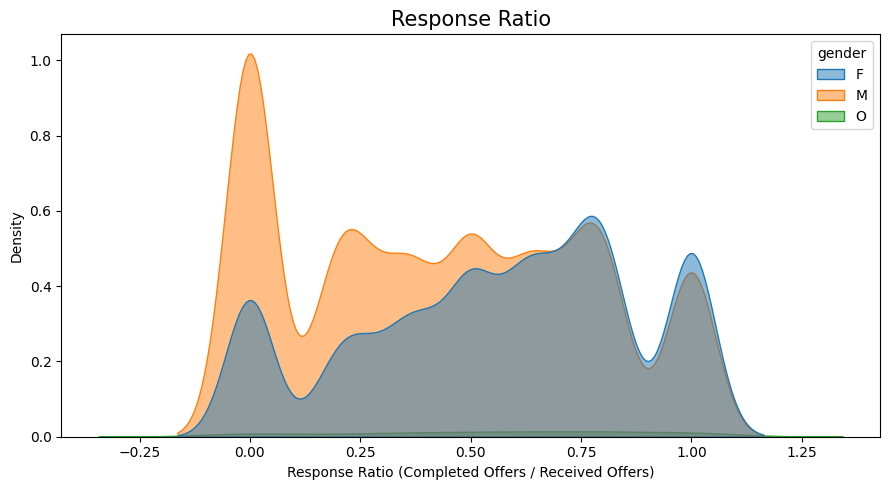

In [29]:
plt.figure(figsize=(9, 5))
sns.kdeplot(data=df_mart, x='response_ratio', hue='gender', fill=True, alpha=0.5)
plt.title('Response Ratio', fontsize=15)
plt.xlabel('Response Ratio (Completed Offers / Received Offers)')
plt.ylabel('Density')
plt.tight_layout()
plt.show()

### 6-4. 성별 반응률 차이 검정: 독립표본 t-검정(Welch's t-test)

In [30]:
response_male   = df_mart[df_mart['gender'] == 'M']['response_ratio'].dropna()
response_female = df_mart[df_mart['gender'] == 'F']['response_ratio'].dropna()

t_stat, p_val = stats.ttest_ind(response_male, response_female, equal_var=False)

print(f'남성 평균 반응률: {response_male.mean():.4f}')
print(f'여성 평균 반응률: {response_female.mean():.4f}')
print(f'\nWelch t-검정 결과: t = {t_stat:.4f}, p = {p_val:.4e}')

if p_val < 0.05:
    print('→ 유의수준 0.05에서 성별 간 오퍼 반응률에 통계적으로 유의한 차이가 존재한다.')
else:
    print('→ 유의수준 0.05에서 성별 간 오퍼 반응률에 통계적으로 유의한 차이가 없다.')

남성 평균 반응률: 0.4312
여성 평균 반응률: 0.5635

Welch t-검정 결과: t = -24.6041, p = 7.7529e-131
→ 유의수준 0.05에서 성별 간 오퍼 반응률에 통계적으로 유의한 차이가 존재한다.


### 6-5. 연령대별 반응률 분석

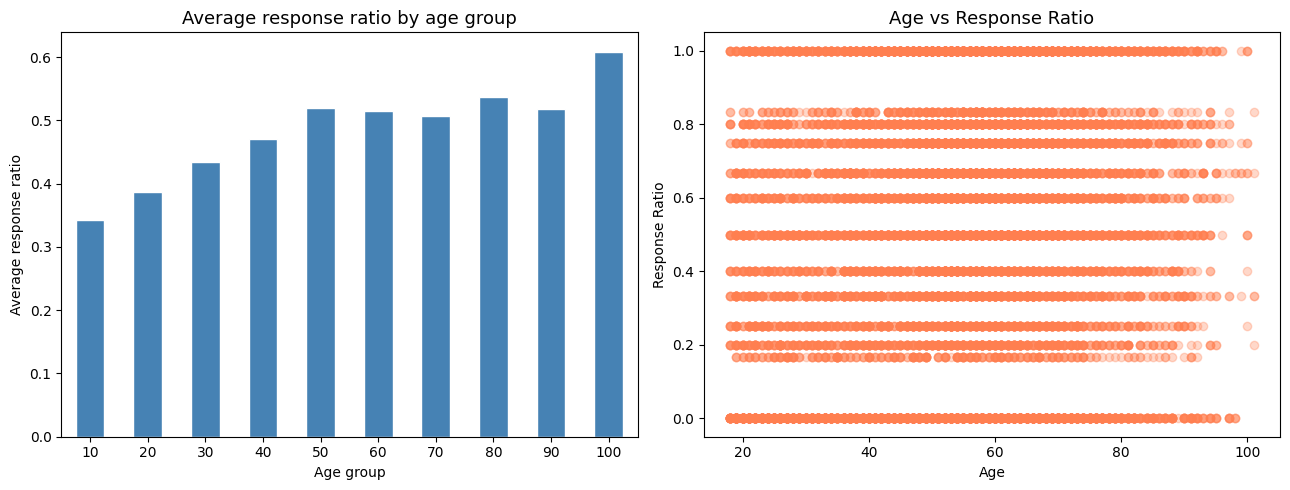

Average response ratio by age group:
age_grp
10     0.3420
20     0.3875
30     0.4338
40     0.4714
50     0.5203
60     0.5154
70     0.5076
80     0.5374
90     0.5176
100    0.6088
Name: response_ratio, dtype: float64


In [31]:
# 연령대 파생 변수 생성
df_mart['age_grp'] = (df_mart['age'] // 10) * 10

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# 연령대별 평균 반응률
age_response = df_mart.groupby('age_grp')['response_ratio'].mean()
age_response.plot(kind='bar', ax=axes[0], color='steelblue', edgecolor='white')
axes[0].set_title('Average response ratio by age group', fontsize=13)
axes[0].set_xlabel('Age group')
axes[0].set_ylabel('Average response ratio')
axes[0].tick_params(axis='x', rotation=0)

# 산점도: 나이 vs 반응률
axes[1].scatter(df_mart['age'], df_mart['response_ratio'], alpha=0.3, color='coral')
axes[1].set_title('Age vs Response Ratio', fontsize=13)
axes[1].set_xlabel('Age')
axes[1].set_ylabel('Response Ratio')

plt.tight_layout()
plt.show()

print('Average response ratio by age group:')
print(age_response.round(4))

### 6-6. 가입 연도별 반응률 추이 분석

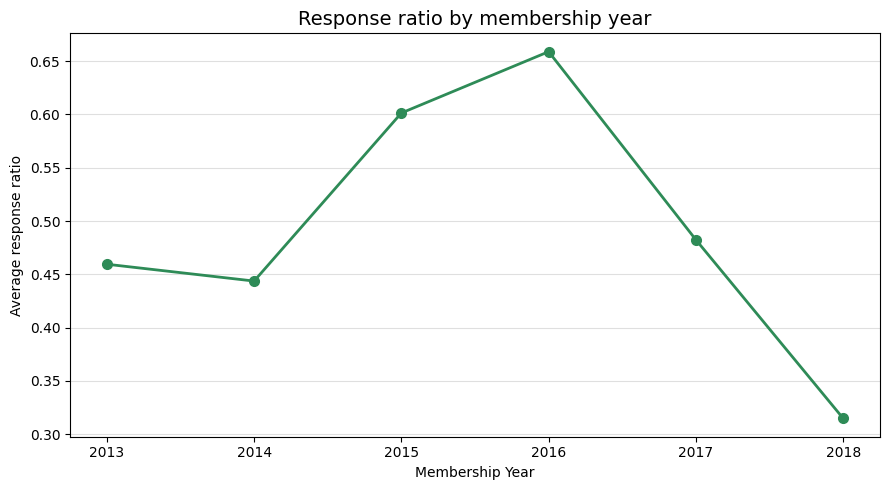

Response ratio by membership year:
n_year
2013    0.4594
2014    0.4436
2015    0.6014
2016    0.6590
2017    0.4824
2018    0.3147
Name: response_ratio, dtype: float64


In [32]:
year_response = df_mart.groupby('n_year')['response_ratio'].mean()

plt.figure(figsize=(9, 5))
year_response.plot(marker='o', color='seagreen', linewidth=2, markersize=7)
plt.title('Response ratio by membership year', fontsize=14)
plt.xlabel('Membership Year')
plt.ylabel('Average response ratio')
plt.grid(axis='y', alpha=0.4)
plt.tight_layout()
plt.show()

print('Response ratio by membership year:')
print(year_response.round(4))

---
## 7단계: 고객 중심 마트 테이블 최종 결과 확인

In [33]:
print('최종 고객 중심 마트 테이블(df_mart) 컬럼 정의')
column_desc = {
    'id'              : '고객 고유 식별자',
    'gender'          : '성별 (M/F)',
    'age'             : '나이',
    'became_member_on': '회원 가입일',
    'income'          : '연간 소득',
    'n_year'          : '회원 가입 연도',
    'offer_received'  : '수신한 오퍼 총 건수',
    'response_cnt'    : '완료한 오퍼 건수',
    'tr_cnt'          : '거래 건수',
    'tr_amt'          : '거래 총 금액',
    'bogo_cnt'        : '수신한 BOGO 오퍼 건수',
    'dc_cnt'          : '수신한 Discount 오퍼 건수',
    'info_cnt'        : '수신한 Informational 오퍼 건수',
    'bogo_response'   : '완료한 BOGO 오퍼 건수',
    'dc_response'     : '완료한 Discount 오퍼 건수',
    'info_response'   : '완료한 Informational 오퍼 건수',
    'response_ratio'  : '전체 오퍼 반응률',
    'bogo_ratio'      : 'BOGO 오퍼 반응률',
    'dc_ratio'        : 'Discount 오퍼 반응률',
    'info_ratio'      : 'Informational 오퍼 반응률',
    'segment'         : '고객 세그먼트 (BOGO / DC / BOGO&DC / no preference)',
    'age_grp'         : '연령대 (10년 단위)'
}
for col, desc in column_desc.items():
    print(f'  {col:<20} : {desc}')

print(f'\n총 고객 수: {len(df_mart):,}명  |  컬럼 수: {df_mart.shape[1]}개')
df_mart.head(10)

최종 고객 중심 마트 테이블(df_mart) 컬럼 정의
  id                   : 고객 고유 식별자
  gender               : 성별 (M/F)
  age                  : 나이
  became_member_on     : 회원 가입일
  income               : 연간 소득
  n_year               : 회원 가입 연도
  offer_received       : 수신한 오퍼 총 건수
  response_cnt         : 완료한 오퍼 건수
  tr_cnt               : 거래 건수
  tr_amt               : 거래 총 금액
  bogo_cnt             : 수신한 BOGO 오퍼 건수
  dc_cnt               : 수신한 Discount 오퍼 건수
  info_cnt             : 수신한 Informational 오퍼 건수
  bogo_response        : 완료한 BOGO 오퍼 건수
  dc_response          : 완료한 Discount 오퍼 건수
  info_response        : 완료한 Informational 오퍼 건수
  response_ratio       : 전체 오퍼 반응률
  bogo_ratio           : BOGO 오퍼 반응률
  dc_ratio             : Discount 오퍼 반응률
  info_ratio           : Informational 오퍼 반응률
  segment              : 고객 세그먼트 (BOGO / DC / BOGO&DC / no preference)
  age_grp              : 연령대 (10년 단위)

총 고객 수: 14,820명  |  컬럼 수: 22개


,gender,age,id,became_member_on,income,n_year,offer_received,response_cnt,tr_cnt,tr_amt,...,info_cnt,bogo_response,dc_response,info_response,response_ratio,bogo_ratio,dc_ratio,info_ratio,segment,age_grp
0,F,55,0610b486422d4921ae7d2bf64640c50b,2017-07-15,112000.0,2017,2,1,3,77.01,...,1,1,0,0,0.500000,1.00,NaN,0.0,BOGO,50
1,F,75,78afa995795e4d85b5d9ceeca43f5fef,2017-05-09,100000.0,2017,4,3,7,159.27,...,1,3,0,0,0.750000,1.00,NaN,0.0,BOGO,70
2,M,68,e2127556f4f64592b11af22de27a7932,2018-04-26,70000.0,2018,4,2,3,57.73,...,1,1,1,0,0.500000,1.00,0.500000,0.0,BOGO,60
3,M,65,389bc3fa690240e798340f5a15918d5c,2018-02-09,53000.0,2018,6,5,3,36.43,...,0,3,2,0,0.833333,0.75,1.000000,NaN,BOGO & DC,60
4,M,58,2eeac8d8feae4a8cad5a6af0499a211d,2017-11-11,51000.0,2017,3,1,4,15.62,...,1,0,1,0,0.333333,NaN,0.500000,0.0,no preference,50
5,F,61,aa4862eba776480b8bb9c68455b8c2e1,2017-09-11,57000.0,2017,5,3,6,85.55,...,1,3,0,0,0.600000,1.00,0.000000,0.0,BOGO,60
6,M,26,e12aeaf2d47d42479ea1c4ac3d8286c6,2014-02-13,46000.0,2014,6,1,11,56.22,...,0,0,1,0,0.166667,0.00,0.200000,NaN,no preference,20
7,F,62,31dda685af34476cad5bc968bdb01c53,2016-02-11,71000.0,2016,6,4,8,160.25,...,0,0,4,0,0.666667,NaN,0.666667,NaN,DC,60
8,M,49,62cf5e10845442329191fc246e7bcea3,2014-11-13,52000.0,2014,3,1,9,144.11,...,1,1,0,0,0.333333,1.00,0.000000,0.0,BOGO,40
9,M,57,6445de3b47274c759400cd68131d91b4,2017-12-31,42000.0,2017,5,2,6,19.10,...,1,1,1,0,0.400000,0.50,0.500000,0.0,no preference,50


In [34]:
df_mart[['response_ratio', 'bogo_ratio', 'dc_ratio', 'info_ratio',
         'tr_cnt', 'tr_amt', 'offer_received', 'response_cnt']].describe().round(4)

,response_ratio,bogo_ratio,dc_ratio,info_ratio,tr_cnt,tr_amt,offer_received,response_cnt
count,14820.0000,13082.0000,13042.0000,9200.0,14820.0000,14820.0000,14820.0000,14820.0000
mean,0.4875,0.5716,0.6440,0.0,8.3629,117.0508,4.4872,2.1892
std,0.3310,0.4392,0.4248,0.0,5.1828,129.9800,1.0717,1.5819
min,0.0000,0.0000,0.0000,0.0,0.0000,0.0000,1.0000,0.0000
25%,0.2000,0.0000,0.0000,0.0,4.0000,31.4575,4.0000,1.0000
50%,0.5000,0.6667,1.0000,0.0,7.0000,87.0750,5.0000,2.0000
75%,0.7500,1.0000,1.0000,0.0,11.0000,160.9725,5.0000,3.0000
max,1.0000,1.0000,1.0000,0.0,36.0000,1608.6900,6.0000,6.0000


---
## 요약 및 결론

### 1) ERD 요약
- `profile`(고객) — `transcript`(이벤트 로그): **1 : N** 관계 (`profile.id = transcript.person`)
- `portfolio`(오퍼) — `transcript`(이벤트 로그): **1 : N** 관계 (`portfolio.id ⊂ transcript.value`)

### 2) 고객 중심 마트 테이블 구축 결과
- `df_transcript` 의 개별 이벤트 로그를 고객 단위로 집계하여 **고객 1행(row)** 구조의 마트 테이블(`df_mart`)을 구성하였다.
- 오퍼 유형(BOGO, Discount, Informational)별 수신 횟수와 완료 횟수를 개별 컬럼으로 관리함으로써 세분화된 반응률 분석이 가능하다.

### 3) 주요 분석 시사점
- **Discount** 오퍼 우선 발송 전략:
Discount 오퍼의 평균 반응률(0.6440)은 BOGO 오퍼(0.5716)보다 약 7% 포인트 높으며, 중앙값이 1.0으로 나타나 절반 이상의 고객이 수신한 Discount 오퍼 전체를 완료하였다. 오퍼 발송 예산이 제한된 상황에서는 Discount 오퍼를 우선적으로 배분하는 것이 캠페인 효율 극대화에 유리하다.
- **no preference** 세그먼트에 대한 이탈 방지 전략:
약 34%(5,026명)를 차지하는 no preference 고객군은 BOGO와 Discount 오퍼 모두에 50% 이하의 반응률을 보인다. 이 집단은 오퍼 무관심층이 아니라 오퍼 조합 및 난이도(difficulty)에 민감할 가능성이 있다. 해당 집단에 대해서는 낮은 난이도의 소액 Discount 오퍼 또는 informational 오퍼를 통한 브랜드 노출 전략을 우선 적용하기 중요하다.
- **Informational** 오퍼의 역할 재정의:
info_ratio가 전체적으로 0으로 측정된 것은 해당 오퍼 유형이 offer completed 이벤트를 발생시키지 않는 설계 구조에 기인한다. 따라서 Informational 오퍼의 효과는 반응률이 아닌 해당 오퍼 수신 전후의 거래 건수(tr_cnt) 및 거래 금액(tr_amt) 변화를 통해 간접적으로 측정하는 방법론으로 전환할 필요가 있다. 이는 향후 연구 과제로 설정할 수 있다.
- **고연령·장기 회원** 타깃 집중 전략:
연령대별 평균 반응률은 10대 0.34에서 50대 이상 약 0.51–0.54로 연령이 높을수록 증가한다. 가입 연도별로는 2015–2016년 가입 고객의 반응률이 가장 높고(0.60–0.66), 2018년 신규 가입 고객이 가장 낮다(0.31). 이 두 집단은 고가치 고객(High-Value Customer)으로 분류하여 우선 오퍼 발송 대상으로 설정하고, 충성도 유지 프로그램과 연계하는 전략이 효과적일 것으로 판단된다.